# Regularization: Preventing Overfitting in Machine Learning

## What You'll Learn
- **What is overfitting** and why it's a problem
- **Visual demonstration** of overfitting with real examples
- **How regularization works** to fix overfitting
- **Different types of regularization**: L1 (Lasso), L2 (Ridge), and Elastic Net
- **Interactive examples** you can experiment with
- **Real-world applications** and when to use each type

---

## 1. Setup and Introduction

First, let's import the libraries we'll need for our visualizations.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seed for reproducibility
np.random.seed(42)

print("✅ All libraries loaded successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ All libraries loaded successfully!
NumPy version: 2.5.3
Pandas version: 3.0.6


## 2. The Problem: Overfitting

### What is Overfitting?

Imagine you're studying for a test by **memorizing** every practice problem instead of **understanding** the concepts. You'll do great on those exact problems, but struggle with new questions!

**Overfitting** is when a machine learning model does exactly this:
- It memorizes the training data (including the noise and errors)
- It performs poorly on new, unseen data
- The model is too complex for the problem

### Visual Example

Let's create a simple dataset and see overfitting in action.

In [2]:
# Create a simple dataset: true relationship is roughly quadratic with some noise
n_samples = 30
X = np.linspace(0, 10, n_samples)

# True underlying function: y = 0.5*x^2 - 2*x + 3
y_true = 0.5 * X**2 - 2 * X + 3

# Add noise to simulate real-world data
noise = np.random.normal(0, 3, n_samples)
y = y_true + noise

# Create test data (more points for smooth curve visualization)
X_test = np.linspace(0, 10, 100)
y_test_true = 0.5 * X_test**2 - 2 * X_test + 3

# Reshape for sklearn
X = X.reshape(-1, 1)
X_test_plot = X_test.reshape(-1, 1)

print(f"Created dataset with {n_samples} training points")
print(f"X range: [{X.min():.2f}, {X.max():.2f}]")
print(f"y range: [{y.min():.2f}, {y.max():.2f}]")

Created dataset with 30 training points
X range: [0.00, 10.00]
y range: [-1.66, 32.12]


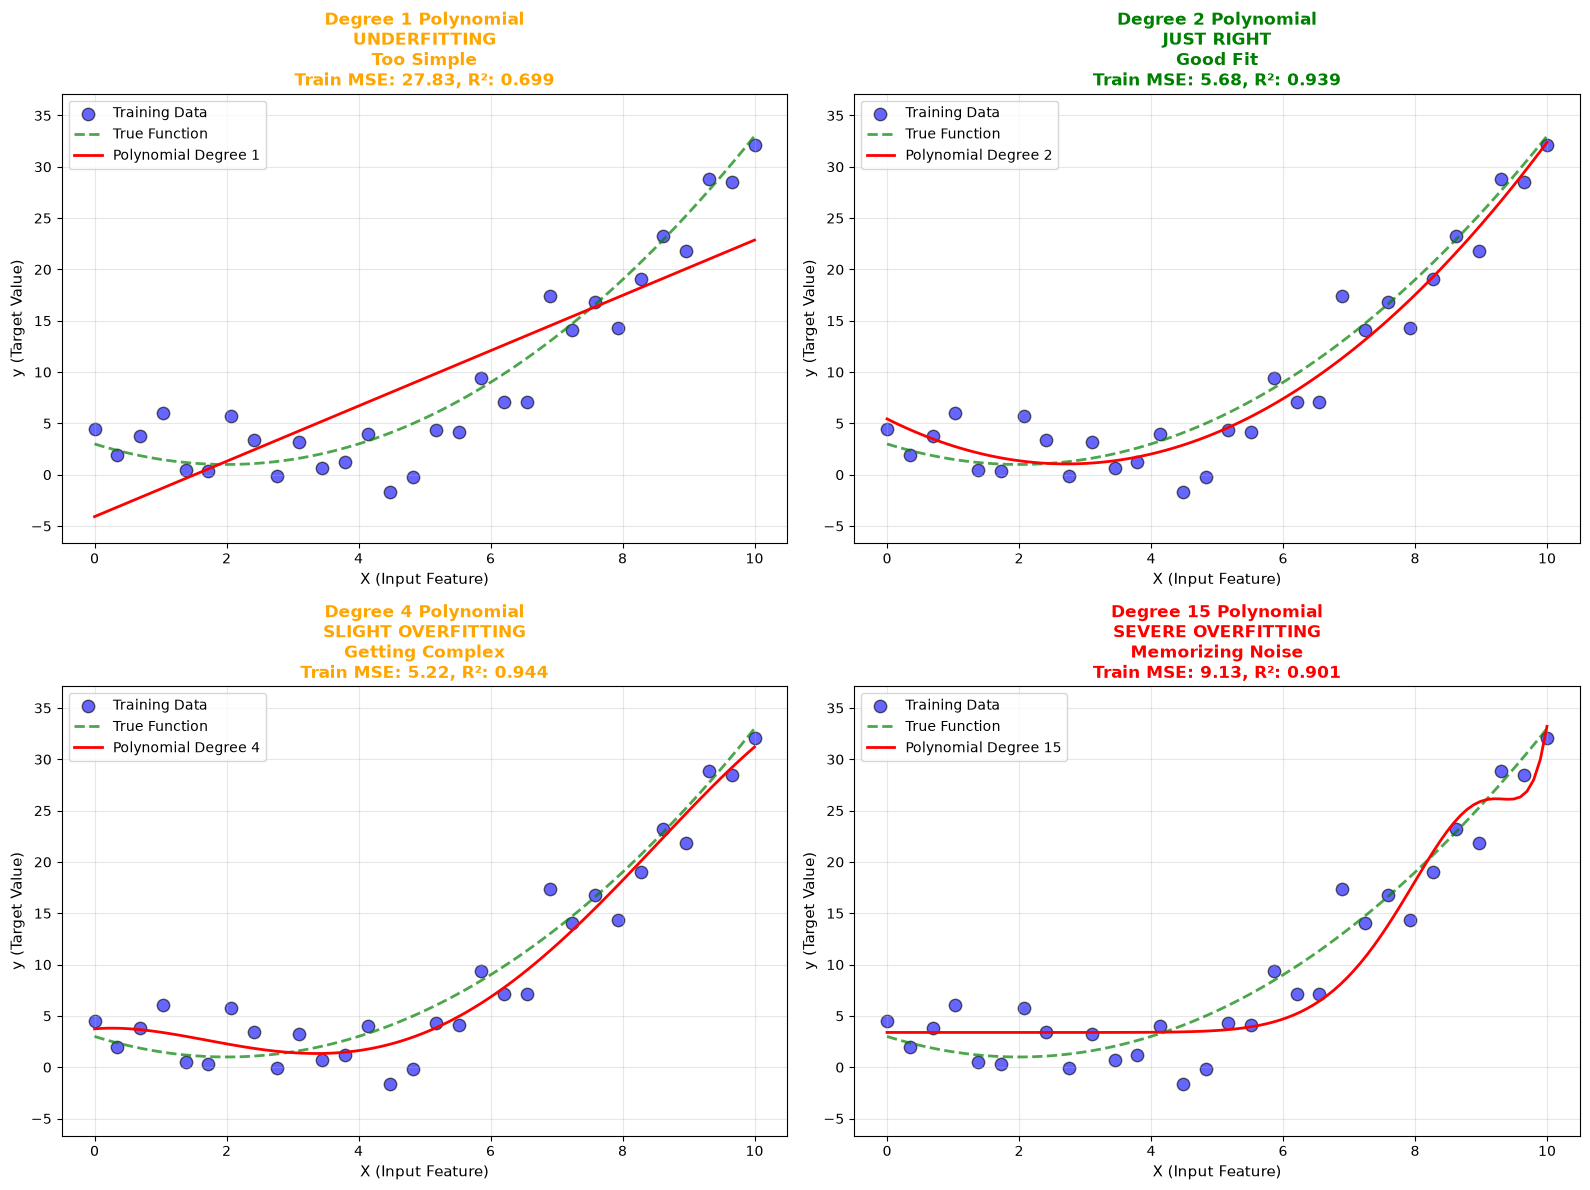


🔍 WHAT YOU'RE SEEING:

📊 DEGREE 1 (Linear): UNDERFITTING
   - The line is too simple to capture the curved pattern
   - Model is too rigid - can't adapt to the data shape
   - Won't perform well on training OR test data

✅ DEGREE 2 (Quadratic): JUST RIGHT
   - Captures the general trend without memorizing noise
   - Balances complexity and simplicity
   - Will generalize well to new data

⚠️  DEGREE 4: SLIGHT OVERFITTING
   - Starting to chase individual data points
   - More wiggly than the true pattern
   - May struggle with new data

❌ DEGREE 15: SEVERE OVERFITTING
   - Extremely wiggly curve trying to hit every point exactly
   - Memorizing noise instead of learning the pattern
   - Will fail badly on new data (look at the wild swings!)
   - This is where REGULARIZATION helps!


In [3]:
# Fit polynomial models of different complexity
degrees = [1, 2, 4, 15]  # Linear, Quadratic, Quartic, and Very High Degree

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for idx, degree in enumerate(degrees):
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    X_test_poly = poly.transform(X_test_plot)
    
    # Fit model
    model = LinearRegression()
    model.fit(X_poly, y)
    
    # Predict
    y_pred_train = model.predict(X_poly)
    y_pred_test = model.predict(X_test_poly)
    
    # Calculate metrics
    train_mse = mean_squared_error(y, y_pred_train)
    train_r2 = r2_score(y, y_pred_train)
    
    # Plot
    axes[idx].scatter(X, y, alpha=0.6, s=80, label='Training Data', color='blue', edgecolors='black', linewidths=1)
    axes[idx].plot(X_test, y_test_true, 'g--', linewidth=2, alpha=0.7, label='True Function')
    axes[idx].plot(X_test, y_pred_test, 'r-', linewidth=2, label=f'Polynomial Degree {degree}')
    
    # Add title with interpretation
    if degree == 1:
        interpretation = "UNDERFITTING\nToo Simple"
        color = 'orange'
    elif degree == 2:
        interpretation = "JUST RIGHT\nGood Fit"
        color = 'green'
    elif degree == 4:
        interpretation = "SLIGHT OVERFITTING\nGetting Complex"
        color = 'orange'
    else:
        interpretation = "SEVERE OVERFITTING\nMemorizing Noise"
        color = 'red'
    
    axes[idx].set_title(f'Degree {degree} Polynomial\n{interpretation}\nTrain MSE: {train_mse:.2f}, R²: {train_r2:.3f}', 
                       fontsize=12, fontweight='bold', color=color)
    axes[idx].set_xlabel('X (Input Feature)', fontsize=11)
    axes[idx].set_ylabel('y (Target Value)', fontsize=11)
    axes[idx].legend(loc='best', fontsize=10)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([y.min()-5, y.max()+5])

plt.tight_layout()
plt.show()

print("\n🔍 WHAT YOU'RE SEEING:")
print("=" * 60)
print("\n📊 DEGREE 1 (Linear): UNDERFITTING")
print("   - The line is too simple to capture the curved pattern")
print("   - Model is too rigid - can't adapt to the data shape")
print("   - Won't perform well on training OR test data")

print("\n✅ DEGREE 2 (Quadratic): JUST RIGHT")
print("   - Captures the general trend without memorizing noise")
print("   - Balances complexity and simplicity")
print("   - Will generalize well to new data")

print("\n⚠️  DEGREE 4: SLIGHT OVERFITTING")
print("   - Starting to chase individual data points")
print("   - More wiggly than the true pattern")
print("   - May struggle with new data")

print("\n❌ DEGREE 15: SEVERE OVERFITTING")
print("   - Extremely wiggly curve trying to hit every point exactly")
print("   - Memorizing noise instead of learning the pattern")
print("   - Will fail badly on new data (look at the wild swings!)")
print("   - This is where REGULARIZATION helps!")

## 3. The Solution: Regularization

### What is Regularization?

**Regularization** is like adding a "penalty for complexity" to your model:

- It discourages the model from fitting too closely to the training data
- It keeps model coefficients small and manageable
- It helps the model focus on the most important patterns

**Analogy**: Think of regularization as a teacher who tells you:
> "Your answer is correct, but if you use a simpler explanation, you'll get bonus points!"

### Types of Regularization

1. **L2 Regularization (Ridge)**
   - Adds penalty proportional to the **square** of coefficient values
   - Makes coefficients smaller but keeps all features
   - Formula: `Loss + α * Σ(coefficient²)`

2. **L1 Regularization (Lasso)**
   - Adds penalty proportional to the **absolute** value of coefficients
   - Can force some coefficients to exactly zero (feature selection)
   - Formula: `Loss + α * Σ|coefficient|`

3. **Elastic Net**
   - Combines both L1 and L2
   - Gets benefits of both approaches
   - Formula: `Loss + α₁ * Σ|coefficient| + α₂ * Σ(coefficient²)`

**Key parameter: α (alpha)** - Controls regularization strength
- α = 0: No regularization (might overfit)
- α = small: Light regularization
- α = large: Strong regularization (might underfit)

## 4. Visual Demonstration: Regularization in Action

Let's take our overfitting problem (degree 15 polynomial) and fix it with regularization!

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85489/4202903327.py:70: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85489/4202903327.py:70: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


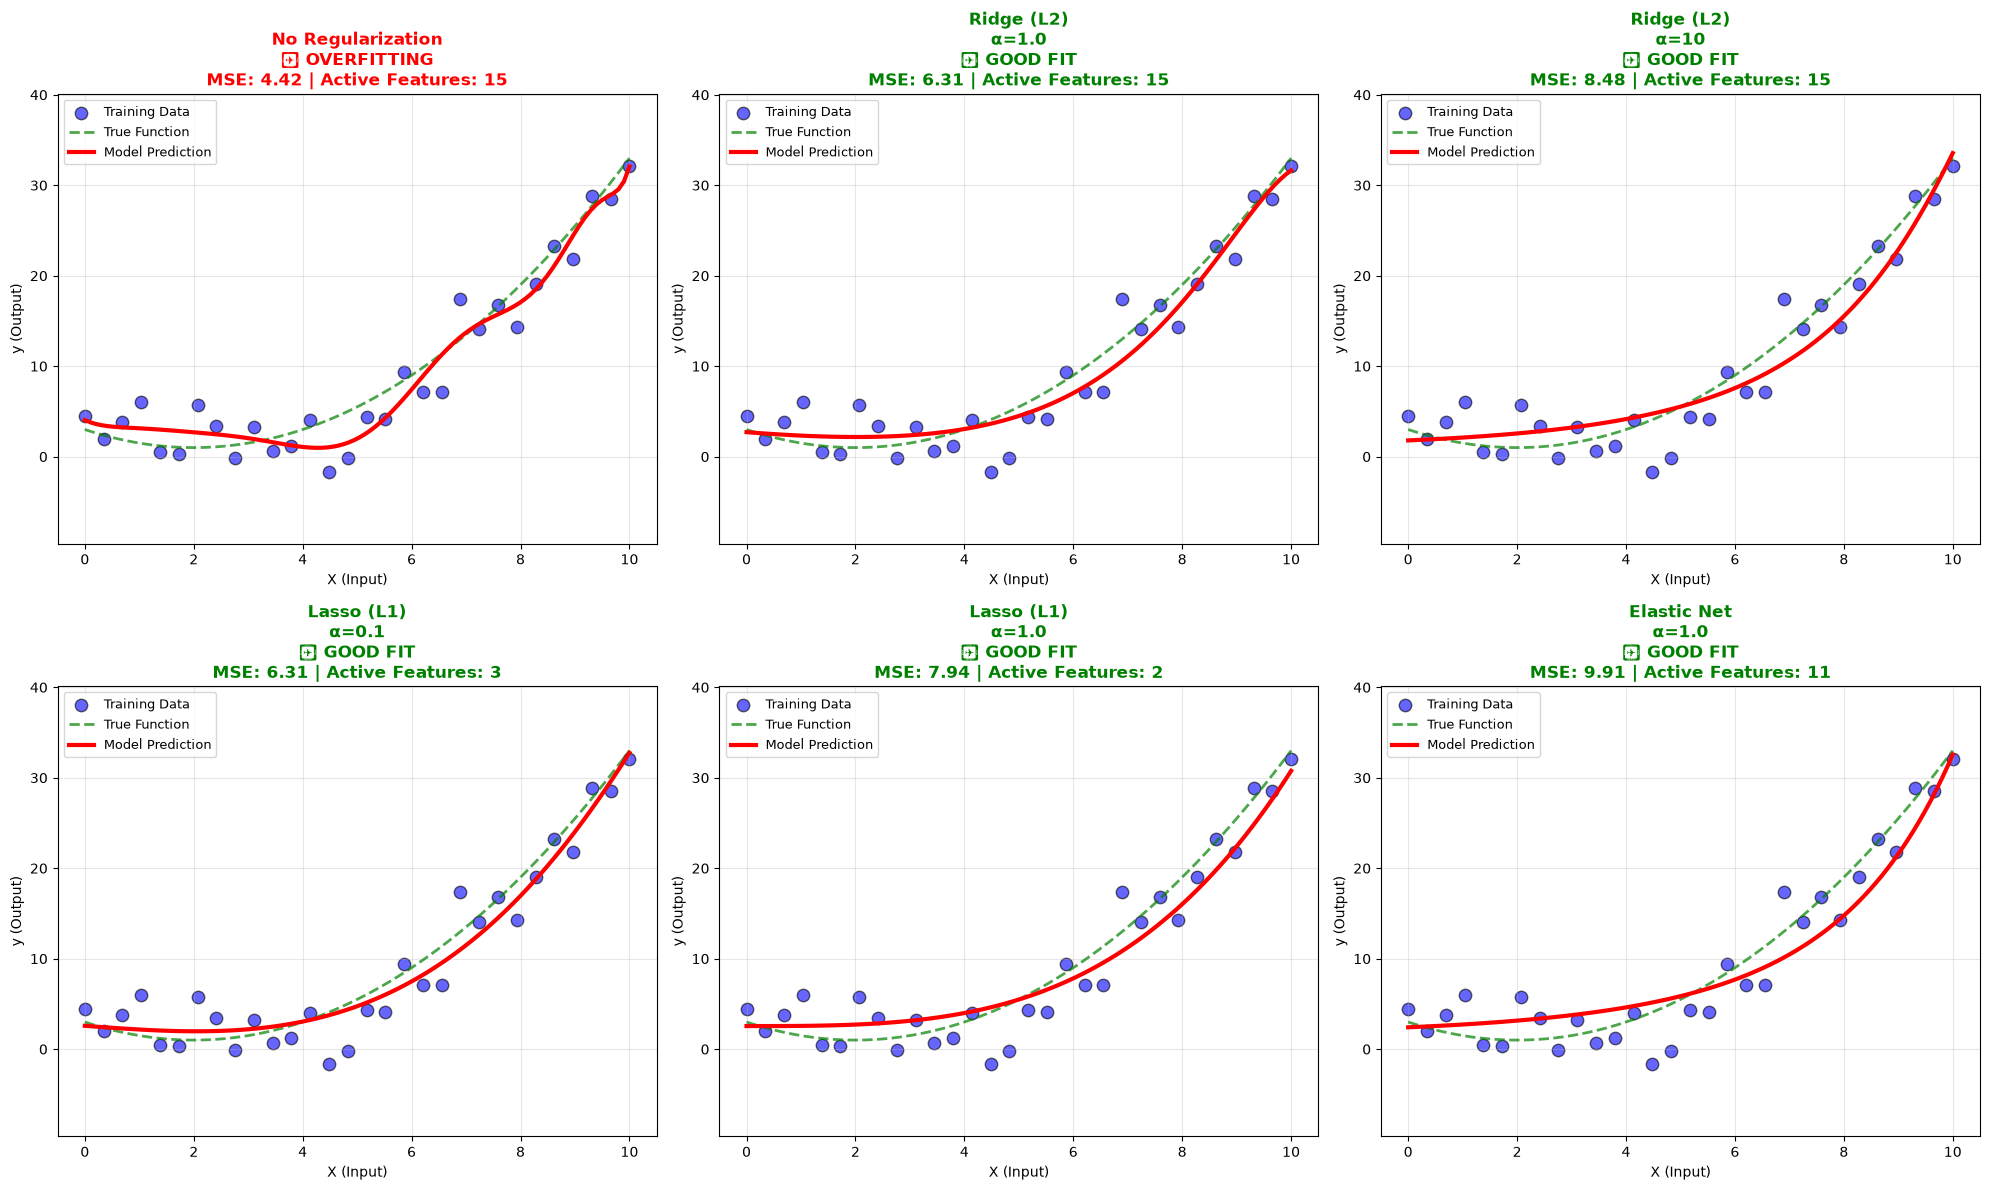


🔍 INTERPRETATION GUIDE:

❌ NO REGULARIZATION:
   - Wild oscillations trying to hit every point
   - Uses all 15 polynomial terms
   - Would fail on new data

✅ RIDGE (L2) REGULARIZATION:
   - α=1.0: Smooths the curve significantly
   - α=10: Even smoother, closer to true pattern
   - Keeps all features but shrinks coefficients
   - Good when all features might be relevant

✅ LASSO (L1) REGULARIZATION:
   - α=0.1: Some smoothing, keeps most features
   - α=1.0: Much smoother, eliminates many features
   - Forces some coefficients to exactly zero
   - Good for automatic feature selection

✅ ELASTIC NET:
   - Combines benefits of Ridge and Lasso
   - Can select features AND shrink coefficients
   - Often a good middle-ground choice


In [4]:
# Use high-degree polynomial (prone to overfitting)
degree = 15
poly = PolynomialFeatures(degree=degree)
X_poly = poly.fit_transform(X)
X_test_poly = poly.transform(X_test_plot)

# Scale features (important for regularization)
scaler = StandardScaler()
X_poly_scaled = scaler.fit_transform(X_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

# Train different models
models = {
    'No Regularization': LinearRegression(),
    'Ridge (L2)\nα=1.0': Ridge(alpha=1.0),
    'Ridge (L2)\nα=10': Ridge(alpha=10),
    'Lasso (L1)\nα=0.1': Lasso(alpha=0.1, max_iter=10000),
    'Lasso (L1)\nα=1.0': Lasso(alpha=1.0, max_iter=10000),
    'Elastic Net\nα=1.0': ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
}

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_poly_scaled, y)
    
    # Predict
    y_pred_train = model.predict(X_poly_scaled)
    y_pred_test = model.predict(X_test_poly_scaled)
    
    # Metrics
    train_mse = mean_squared_error(y, y_pred_train)
    train_r2 = r2_score(y, y_pred_train)
    
    # Count non-zero coefficients (for Lasso)
    if hasattr(model, 'coef_'):
        n_nonzero = np.sum(np.abs(model.coef_) > 1e-5)
    else:
        n_nonzero = len(model.coef_)
    
    # Plot
    axes[idx].scatter(X, y, alpha=0.6, s=80, label='Training Data', color='blue', edgecolors='black', linewidths=1)
    axes[idx].plot(X_test, y_test_true, 'g--', linewidth=2, alpha=0.7, label='True Function')
    axes[idx].plot(X_test, y_pred_test, 'r-', linewidth=3, label='Model Prediction')
    
    # Determine if this is a good fit
    curve_range = np.ptp(y_pred_test)
    data_range = np.ptp(y)
    
    if idx == 0:
        quality = "❌ OVERFITTING"
        color = 'red'
    elif curve_range > data_range * 1.5:
        quality = "⚠️ STILL WIGGLY"
        color = 'orange'
    else:
        quality = "✅ GOOD FIT"
        color = 'green'
    
    axes[idx].set_title(f'{name}\n{quality}\nMSE: {train_mse:.2f} | Active Features: {n_nonzero}', 
                       fontsize=12, fontweight='bold', color=color)
    axes[idx].set_xlabel('X (Input)', fontsize=10)
    axes[idx].set_ylabel('y (Output)', fontsize=10)
    axes[idx].legend(loc='best', fontsize=9)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([y.min()-8, y.max()+8])

plt.tight_layout()
plt.show()

print("\n🔍 INTERPRETATION GUIDE:")
print("=" * 60)
print("\n❌ NO REGULARIZATION:")
print("   - Wild oscillations trying to hit every point")
print("   - Uses all 15 polynomial terms")
print("   - Would fail on new data")

print("\n✅ RIDGE (L2) REGULARIZATION:")
print("   - α=1.0: Smooths the curve significantly")
print("   - α=10: Even smoother, closer to true pattern")
print("   - Keeps all features but shrinks coefficients")
print("   - Good when all features might be relevant")

print("\n✅ LASSO (L1) REGULARIZATION:")
print("   - α=0.1: Some smoothing, keeps most features")
print("   - α=1.0: Much smoother, eliminates many features")
print("   - Forces some coefficients to exactly zero")
print("   - Good for automatic feature selection")

print("\n✅ ELASTIC NET:")
print("   - Combines benefits of Ridge and Lasso")
print("   - Can select features AND shrink coefficients")
print("   - Often a good middle-ground choice")

## 5. Understanding Coefficient Behavior

Let's visualize how regularization affects the model coefficients (the weights each feature gets).

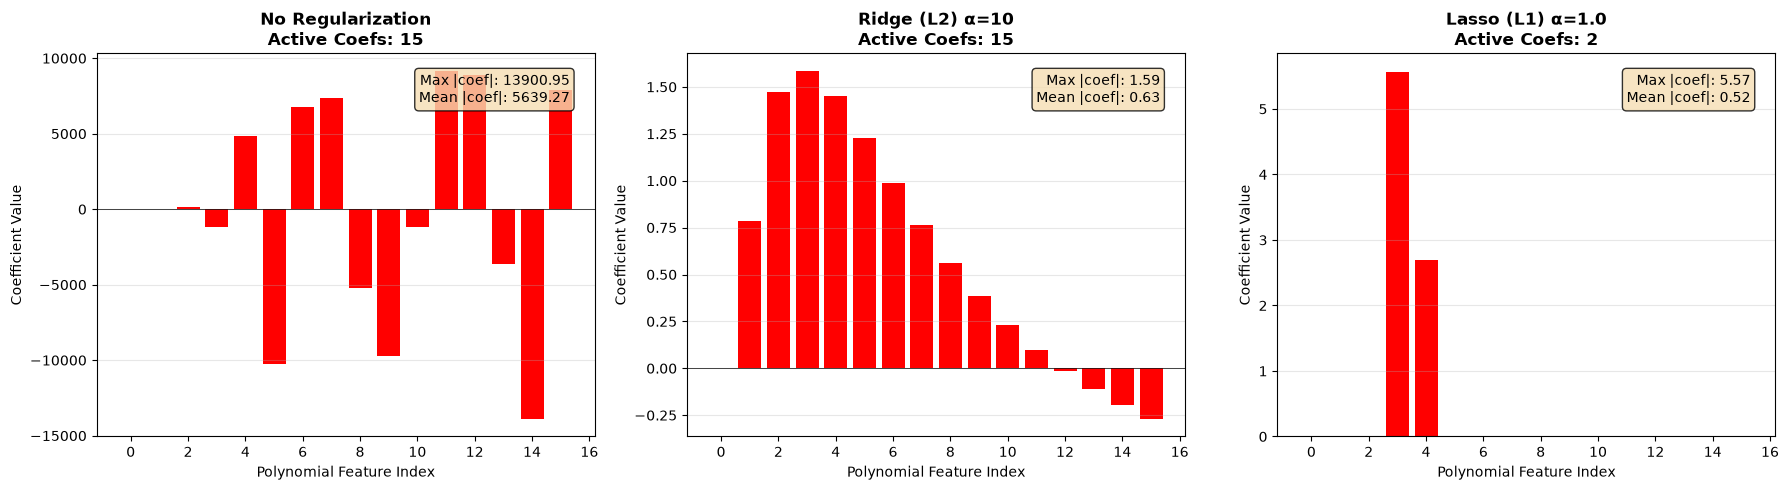


📊 COEFFICIENT ANALYSIS:

🔴 RED BARS = Active coefficients (used by the model)
⚪ GRAY BARS = Near-zero coefficients (effectively removed)

❌ NO REGULARIZATION:
   - Large, unstable coefficients
   - All features used (even irrelevant ones)
   - High variance in coefficient magnitudes

✅ RIDGE (L2):
   - Shrinks all coefficients toward zero
   - Still uses all features (none exactly zero)
   - More stable, smaller coefficients

✅ LASSO (L1):
   - Forces many coefficients to EXACTLY zero
   - Automatic feature selection
   - Keeps only the most important features

💡 KEY INSIGHT:
   Regularization prevents any single feature from having
   too much influence, leading to better generalization!


In [5]:
# Compare coefficients across models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Models to compare
comparison_models = [
    ('No Regularization', LinearRegression()),
    ('Ridge (L2) α=10', Ridge(alpha=10)),
    ('Lasso (L1) α=1.0', Lasso(alpha=1.0, max_iter=10000))
]

for idx, (name, model) in enumerate(comparison_models):
    # Train model
    model.fit(X_poly_scaled, y)
    
    # Get coefficients
    coefs = model.coef_
    
    # Plot
    axes[idx].bar(range(len(coefs)), coefs, color=['red' if abs(c) > 0.01 else 'lightgray' for c in coefs])
    axes[idx].set_title(f'{name}\nActive Coefs: {np.sum(np.abs(coefs) > 0.01)}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Polynomial Feature Index', fontsize=10)
    axes[idx].set_ylabel('Coefficient Value', fontsize=10)
    axes[idx].grid(True, alpha=0.3, axis='y')
    axes[idx].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
    
    # Add statistics
    max_coef = np.max(np.abs(coefs))
    mean_coef = np.mean(np.abs(coefs))
    axes[idx].text(0.95, 0.95, f'Max |coef|: {max_coef:.2f}\nMean |coef|: {mean_coef:.2f}',
                  transform=axes[idx].transAxes,
                  verticalalignment='top',
                  horizontalalignment='right',
                  bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
                  fontsize=10)

plt.tight_layout()
plt.show()

print("\n📊 COEFFICIENT ANALYSIS:")
print("=" * 60)
print("\n🔴 RED BARS = Active coefficients (used by the model)")
print("⚪ GRAY BARS = Near-zero coefficients (effectively removed)")

print("\n❌ NO REGULARIZATION:")
print("   - Large, unstable coefficients")
print("   - All features used (even irrelevant ones)")
print("   - High variance in coefficient magnitudes")

print("\n✅ RIDGE (L2):")
print("   - Shrinks all coefficients toward zero")
print("   - Still uses all features (none exactly zero)")
print("   - More stable, smaller coefficients")

print("\n✅ LASSO (L1):")
print("   - Forces many coefficients to EXACTLY zero")
print("   - Automatic feature selection")
print("   - Keeps only the most important features")

print("\n💡 KEY INSIGHT:")
print("   Regularization prevents any single feature from having")
print("   too much influence, leading to better generalization!")

## 6. Interactive Exploration

Now you can experiment with different regularization strengths yourself!

In [6]:
def explore_regularization(alpha=1.0, degree=15, regularization_type='Ridge'):
    """
    Interactive function to explore regularization effects.
    
    Parameters:
    - alpha: Regularization strength (0 = no regularization, higher = more)
    - degree: Polynomial degree (complexity of the model)
    - regularization_type: Type of regularization (Ridge, Lasso, or Elastic Net)
    """
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    X_test_poly = poly.transform(X_test_plot)
    
    # Scale
    scaler = StandardScaler()
    X_poly_scaled = scaler.fit_transform(X_poly)
    X_test_poly_scaled = scaler.transform(X_test_poly)
    
    # Select model
    if regularization_type == 'Ridge':
        model = Ridge(alpha=alpha)
    elif regularization_type == 'Lasso':
        model = Lasso(alpha=alpha, max_iter=10000)
    else:  # Elastic Net
        model = ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000)
    
    # Train
    model.fit(X_poly_scaled, y)
    
    # Predict
    y_pred_train = model.predict(X_poly_scaled)
    y_pred_test = model.predict(X_test_poly_scaled)
    
    # Metrics
    train_mse = mean_squared_error(y, y_pred_train)
    train_r2 = r2_score(y, y_pred_train)
    n_nonzero = np.sum(np.abs(model.coef_) > 1e-5)
    
    # Create figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    
    # Plot 1: Model fit
    ax1.scatter(X, y, alpha=0.6, s=100, label='Training Data', color='blue', edgecolors='black', linewidths=1.5)
    ax1.plot(X_test, y_test_true, 'g--', linewidth=2.5, alpha=0.7, label='True Function')
    ax1.plot(X_test, y_pred_test, 'r-', linewidth=3, label=f'{regularization_type} Prediction')
    ax1.set_title(f'{regularization_type} Regularization (α={alpha:.2f}, Degree={degree})\n',# +
               #  f'MSE: {train_mse:.2f} | R²: {train_r2:.3f} | Active Features: {n_nonzero}/{len(model.coef_)}',
                 fontsize=13, fontweight='bold')
    ax1.set_xlabel('X (Input Feature)', fontsize=12)
    ax1.set_ylabel('y (Target Value)', fontsize=12)
    ax1.legend(loc='best', fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([y.min()-10, y.max()+10])
    
    # Plot 2: Coefficients
    coefs = model.coef_
    colors = ['red' if abs(c) > 1e-5 else 'lightgray' for c in coefs]
    ax2.bar(range(len(coefs)), coefs, color=colors, edgecolor='black', linewidth=0.5)
    ax2.set_title(f'Model Coefficients\n{n_nonzero} Active (Red) | {len(coefs)-n_nonzero} Zeroed (Gray)',
                 fontsize=13, fontweight='bold')
    ax2.set_xlabel('Feature Index', fontsize=12)
    ax2.set_ylabel('Coefficient Value', fontsize=12)
    ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Add statistics box
    max_coef = np.max(np.abs(coefs))
    mean_coef = np.mean(np.abs(coefs[np.abs(coefs) > 1e-5])) if n_nonzero > 0 else 0
    ax2.text(0.95, 0.95, f'Max |coef|: {max_coef:.3f}\nMean |coef|: {mean_coef:.3f}',
            transform=ax2.transAxes,
            verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.9),
            fontsize=11)
    
    plt.tight_layout()
    plt.show()
    
    # Print interpretation
    curve_range = np.ptp(y_pred_test)
    data_range = np.ptp(y)
    
    print("\n📊 INTERPRETATION:")
    print("=" * 50)
    
    if alpha < 0.01:
        print("⚠️  VERY LOW REGULARIZATION:")
        print("   - Model may be overfitting")
        print("   - Try increasing α for smoother predictions")
    elif alpha > 50:
        print("⚠️  VERY HIGH REGULARIZATION:")
        print("   - Model may be underfitting")
        print("   - Try decreasing α for better fit")
    else:
        print("✅ REASONABLE REGULARIZATION LEVEL")
    
    if curve_range > data_range * 2:
        print("\n⚠️  Model is WIGGLY (might be overfitting)")
        print("   → Increase α or decrease polynomial degree")
    elif curve_range < data_range * 0.3:
        print("\n⚠️  Model is TOO FLAT (might be underfitting)")
        print("   → Decrease α or increase polynomial degree")
    else:
        print("\n✅ Model complexity looks appropriate!")
    
    print(f"\n📈 Active features: {n_nonzero}/{len(coefs)} ({n_nonzero/len(coefs)*100:.1f}%)")
    if regularization_type == 'Lasso' and n_nonzero < len(coefs) * 0.5:
        print("   💡 Lasso has performed automatic feature selection!")

# Create interactive widget
interact(explore_regularization,
         alpha=FloatSlider(value=1.0, min=0.0, max=100.0, step=0.5, 
                          description='α (Regularization Strength)',
                          style={'description_width': 'initial'}),
         degree=IntSlider(value=15, min=2, max=20, step=1,
                         description='Polynomial Degree',
                         style={'description_width': 'initial'}),
         regularization_type=['Ridge', 'Lasso', 'Elastic Net']);

interactive(children=(FloatSlider(value=1.0, description='α (Regularization Strength)', step=0.5, style=Slider…

## 7. Comparing All Three Types Side-by-Side

Let's see how each regularization type performs across different strength levels.

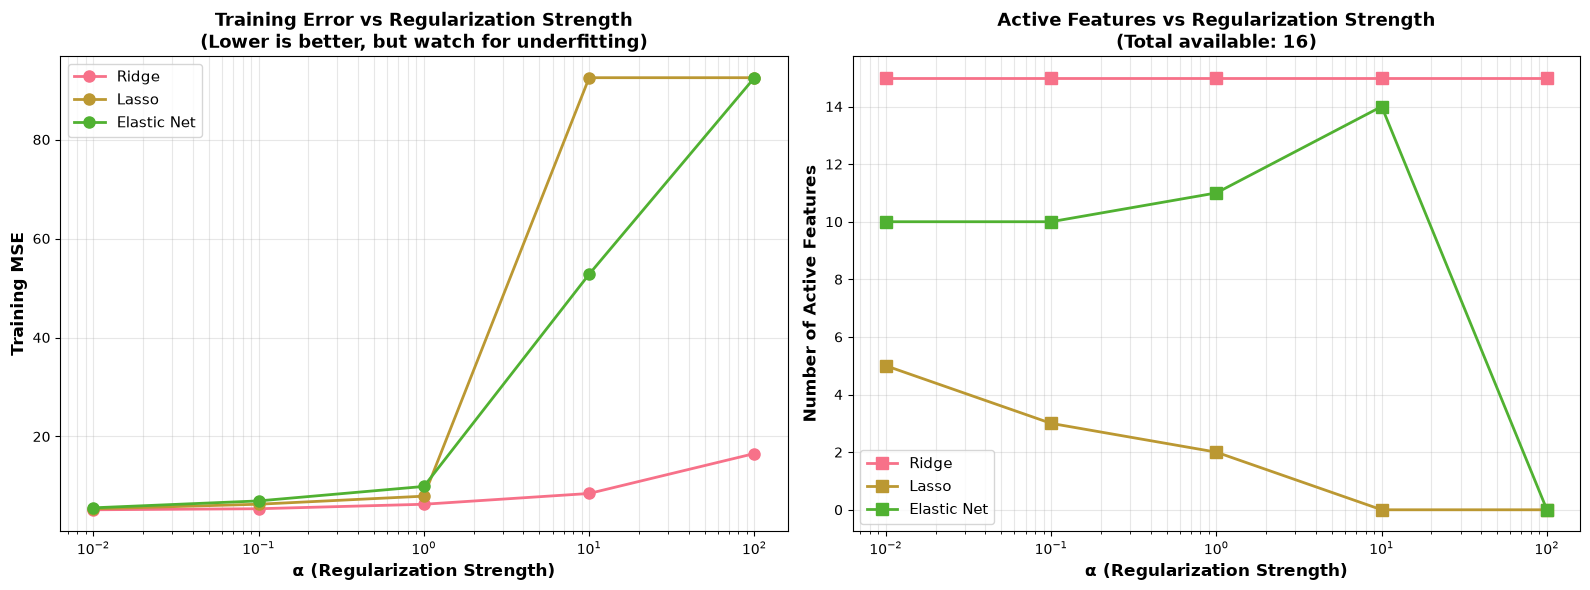


📊 KEY OBSERVATIONS:

🔵 RIDGE (L2) REGULARIZATION:
   ✅ Keeps all features active (no feature elimination)
   ✅ Training error increases smoothly with α
   ✅ Good when you think all features are somewhat relevant
   ⚠️  Can't do automatic feature selection

🔴 LASSO (L1) REGULARIZATION:
   ✅ Aggressively eliminates features (sets to zero)
   ✅ Built-in feature selection
   ✅ Creates simpler, more interpretable models
   ⚠️  May eliminate features that are actually useful

🟣 ELASTIC NET:
   ✅ Balanced approach: some feature selection + shrinkage
   ✅ Gets benefits of both Ridge and Lasso
   ✅ Often a safe default choice
   ⚠️  One more hyperparameter to tune (l1_ratio)

💡 PRACTICAL ADVICE:
   1. Start with α ≈ 1.0 and adjust from there
   2. Use cross-validation to find optimal α
   3. If you want feature selection → try Lasso first
   4. If unsure → try Elastic Net (best of both worlds)
   5. As α ↑: Model becomes simpler but may underfit
   6. As α ↓: Model becomes complex and may over

In [7]:
# Test different alpha values
alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
degree = 15

# Prepare data
poly = PolynomialFeatures(degree=degree)
X_poly = poly.fit_transform(X)
X_test_poly = poly.transform(X_test_plot)

scaler = StandardScaler()
X_poly_scaled = scaler.fit_transform(X_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

# Store results
results = {'alpha': [], 'method': [], 'train_mse': [], 'active_features': []}

for alpha in alphas:
    for method_name, model_class in [('Ridge', Ridge), ('Lasso', Lasso), ('Elastic Net', ElasticNet)]:
        # Create and train model
        if method_name == 'Elastic Net':
            model = model_class(alpha=alpha, l1_ratio=0.5, max_iter=10000)
        else:
            model = model_class(alpha=alpha, max_iter=10000)
        
        model.fit(X_poly_scaled, y)
        
        # Metrics
        y_pred = model.predict(X_poly_scaled)
        mse = mean_squared_error(y, y_pred)
        n_active = np.sum(np.abs(model.coef_) > 1e-5)
        
        results['alpha'].append(alpha)
        results['method'].append(method_name)
        results['train_mse'].append(mse)
        results['active_features'].append(n_active)

# Create DataFrame
results_df = pd.DataFrame(results)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: MSE vs Alpha
for method in ['Ridge', 'Lasso', 'Elastic Net']:
    method_data = results_df[results_df['method'] == method]
    ax1.plot(method_data['alpha'], method_data['train_mse'], marker='o', linewidth=2, markersize=8, label=method)

ax1.set_xscale('log')
ax1.set_xlabel('α (Regularization Strength)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Training MSE', fontsize=12, fontweight='bold')
ax1.set_title('Training Error vs Regularization Strength\n(Lower is better, but watch for underfitting)', 
             fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3, which='both')

# Plot 2: Active Features vs Alpha
for method in ['Ridge', 'Lasso', 'Elastic Net']:
    method_data = results_df[results_df['method'] == method]
    ax2.plot(method_data['alpha'], method_data['active_features'], marker='s', linewidth=2, markersize=8, label=method)

ax2.set_xscale('log')
ax2.set_xlabel('α (Regularization Strength)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Number of Active Features', fontsize=12, fontweight='bold')
ax2.set_title(f'Active Features vs Regularization Strength\n(Total available: {degree+1})', 
             fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

print("\n📊 KEY OBSERVATIONS:")
print("=" * 60)

print("\n🔵 RIDGE (L2) REGULARIZATION:")
print("   ✅ Keeps all features active (no feature elimination)")
print("   ✅ Training error increases smoothly with α")
print("   ✅ Good when you think all features are somewhat relevant")
print("   ⚠️  Can't do automatic feature selection")

print("\n🔴 LASSO (L1) REGULARIZATION:")
print("   ✅ Aggressively eliminates features (sets to zero)")
print("   ✅ Built-in feature selection")
print("   ✅ Creates simpler, more interpretable models")
print("   ⚠️  May eliminate features that are actually useful")

print("\n🟣 ELASTIC NET:")
print("   ✅ Balanced approach: some feature selection + shrinkage")
print("   ✅ Gets benefits of both Ridge and Lasso")
print("   ✅ Often a safe default choice")
print("   ⚠️  One more hyperparameter to tune (l1_ratio)")

print("\n💡 PRACTICAL ADVICE:")
print("   1. Start with α ≈ 1.0 and adjust from there")
print("   2. Use cross-validation to find optimal α")
print("   3. If you want feature selection → try Lasso first")
print("   4. If unsure → try Elastic Net (best of both worlds)")
print("   5. As α ↑: Model becomes simpler but may underfit")
print("   6. As α ↓: Model becomes complex and may overfit")

## 8. Real-World Example: Predicting Hospital Length of Stay

Let's apply regularization to a realistic clinical scenario with many candidate predictors.

### The Scenario

You're tasked with predicting **length of stay (days)** for patients admitted to a general
medical ward. The electronic health record hands you 50 variables recorded at admission:

- Demographics and admission characteristics (age, sex, BMI, admission source, elective vs emergency)
- Vital signs (heart rate, blood pressure, respiratory rate, SpO₂, temperature, GCS)
- Laboratory results (full blood count, renal panel, liver panel, lactate, CRP, troponin, INR)
- Comorbidity flags (diabetes, heart failure, COPD, CKD, cancer, dementia, Charlson index)
- Prior utilization (admissions in the last 12 months, ED visits, home medication count)

But here's the challenge: **most of those 50 variables carry no signal for length of stay.**
Some are redundant with each other, some are noisy, many are simply irrelevant. Only about
10 of them genuinely drive how long a patient stays.

This is exactly the situation Lasso was designed for: a wide, mostly-noise feature set
where you need the model to find the real drivers and set the rest to zero. And there is a
practical reason to care beyond accuracy — every variable you keep is a field somebody has
to extract, validate and monitor, and a model a clinician has to be able to read.

> **A note on the data.** The cohort below is generated with scikit-learn's
> `make_regression` and labelled with plausible EHR variable names. It is entirely
> synthetic and contains no real or identifiable patient information.


In [8]:
# Create a realistic length-of-stay dataset
from sklearn.datasets import make_regression

# Generate synthetic data representing 200 medical-ward admissions.
# Simulated data - no real or identifiable patient information.
X_real, y_real = make_regression(
    n_samples=200,  # 200 admissions
    n_features=50,  # 50 variables pulled from the EHR at admission
    n_informative=10,  # Only 10 of them truly drive length of stay
    noise=20,
    random_state=42
)

# Plausible EHR variable names (exactly 50, one per column)
feature_names = [
    # Demographics and admission characteristics
    'Age_years', 'Sex_Male', 'BMI', 'Admission_Source_ED',
    'Admission_Hour', 'Weekend_Admission', 'Elective_Admission',
    'Transfer_From_LTC',

    # Vital signs at admission
    'Heart_Rate_bpm', 'Systolic_BP_mmHg', 'Diastolic_BP_mmHg',
    'Respiratory_Rate', 'SpO2_pct', 'Temperature_C',
    'Pain_Score', 'GCS_Total',

    # Laboratory results
    'WBC_10e9_L', 'Hemoglobin_g_L', 'Platelets_10e9_L',
    'Sodium_mmol_L', 'Potassium_mmol_L', 'Chloride_mmol_L',
    'Bicarbonate_mmol_L', 'Urea_mmol_L', 'Creatinine_umol_L',
    'eGFR_mL_min', 'Glucose_mmol_L', 'Albumin_g_L',
    'Bilirubin_umol_L', 'ALT_U_L', 'AST_U_L', 'Alk_Phos_U_L',
    'Lactate_mmol_L', 'CRP_mg_L', 'Troponin_ng_L', 'BNP_pg_mL',
    'INR', 'D_Dimer_mg_L_FEU',

    # Comorbidity flags
    'Charlson_Index', 'Diabetes_Flag', 'CHF_Flag', 'COPD_Flag',
    'CKD_Flag', 'Cancer_Flag', 'Dementia_Flag', 'Stroke_History_Flag',

    # Prior utilization
    'Prior_Admissions_12mo', 'Prior_ED_Visits_6mo',
    'Num_Home_Medications', 'Days_Since_Last_Discharge'
]
assert len(feature_names) == X_real.shape[1], "one name per column"

# Split data
X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
    X_real, y_real, test_size=0.3, random_state=42
)

print(f"\U0001fa7a  LENGTH OF STAY DATASET (simulated)")
print(f"=" * 60)
print(f"\U0001f4ca Data Overview:")
print(f"   - Total EHR variables: 50")
print(f"   - Truly informative variables: ~10")
print(f"   - Noise/redundant variables: ~40")
print(f"   - Training samples: {len(X_train_real)} admissions")
print(f"   - Test samples: {len(X_test_real)} admissions")
print(f"\n\U0001f3af Goal: Identify which variables actually predict length of stay!")
print(f"\n\U0001f4a1 Challenge: Every variable kept is a field to extract, validate and monitor.")
print(f"   Can we find which ones to keep and which to drop?")


🩺  LENGTH OF STAY DATASET (simulated)
📊 Data Overview:
   - Total EHR variables: 50
   - Truly informative variables: ~10
   - Noise/redundant variables: ~40
   - Training samples: 140 admissions
   - Test samples: 60 admissions

🎯 Goal: Identify which variables actually predict length of stay!

💡 Challenge: Every variable kept is a field to extract, validate and monitor.
   Can we find which ones to keep and which to drop?


In [9]:
# Compare models on real-world data
from sklearn.model_selection import cross_val_score

# Scale features
scaler_real = StandardScaler()
X_train_real_scaled = scaler_real.fit_transform(X_train_real)
X_test_real_scaled = scaler_real.transform(X_test_real)

# Train different models
models_real = {
    'Linear (No Reg)': LinearRegression(),
    'Ridge (α=1)': Ridge(alpha=1.0),
    'Ridge (α=10)': Ridge(alpha=10.0),
    'Lasso (α=1)': Lasso(alpha=1.0, max_iter=10000),
    'Lasso (α=5)': Lasso(alpha=5.0, max_iter=10000),
    'Elastic Net': ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
}

# Evaluate models
results_real = []

for name, model in models_real.items():
    # Train
    model.fit(X_train_real_scaled, y_train_real)
    
    # Predictions
    y_pred_train = model.predict(X_train_real_scaled)
    y_pred_test = model.predict(X_test_real_scaled)
    
    # Metrics
    train_mse = mean_squared_error(y_train_real, y_pred_train)
    test_mse = mean_squared_error(y_test_real, y_pred_test)
    train_r2 = r2_score(y_train_real, y_pred_train)
    test_r2 = r2_score(y_test_real, y_pred_test)
    
    # Cross-validation
    cv_scores = cross_val_score(model, X_train_real_scaled, y_train_real, 
                                cv=5, scoring='r2')
    
    # Count active features
    if hasattr(model, 'coef_'):
        n_active = np.sum(np.abs(model.coef_) > 1e-5)
    else:
        n_active = X_real.shape[1]
    
    results_real.append({
        'Model': name,
        'Train R²': train_r2,
        'Test R²': test_r2,
        'CV R² (mean)': cv_scores.mean(),
        'CV R² (std)': cv_scores.std(),
        'Train MSE': train_mse,
        'Test MSE': test_mse,
        'Active Variables': n_active,
        'Overfit Gap': train_r2 - test_r2
    })

# Create results DataFrame
results_real_df = pd.DataFrame(results_real)

print("\n📊 MODEL COMPARISON RESULTS:")
print("=" * 90)
print(results_real_df.round(4).to_string(index=False))

# Find best model (by test R²)
best_model_idx = results_real_df['Test R²'].idxmax()
best_model_name = results_real_df.iloc[best_model_idx]['Model']

eliminated = 50 - results_real_df.iloc[best_model_idx]['Active Variables']

print(f"\n\n🏆 BEST MODEL: {best_model_name}")
print(f"   Test R²: {results_real_df.iloc[best_model_idx]['Test R²']:.4f}")
print(f"   Active Variables: {results_real_df.iloc[best_model_idx]['Active Variables']:.0f}/50")
print(f"   Overfitting Gap: {results_real_df.iloc[best_model_idx]['Overfit Gap']:.4f}")
print(f"\n🩺 CLINICAL PAYOFF:")
print(f"   - Can drop {eliminated:.0f} variables from the model!")
print(f"   - Fewer EHR fields to extract, validate and monitor")
print(f"   - A simpler model a clinician can actually review")


📊 MODEL COMPARISON RESULTS:
          Model  Train R²  Test R²  CV R² (mean)  CV R² (std)  Train MSE  Test MSE  Active Variables  Overfit Gap
Linear (No Reg)    0.9880   0.9463        0.9642       0.0118   225.6541  894.3773                50       0.0417
    Ridge (α=1)    0.9879   0.9464        0.9643       0.0109   227.0727  892.8335                50       0.0415
   Ridge (α=10)    0.9824   0.9353        0.9392       0.0160   330.7919 1077.9020                50       0.0471
    Lasso (α=1)    0.9852   0.9612        0.9730       0.0054   279.1141  647.1031                33       0.0240
    Lasso (α=5)    0.9688   0.9522        0.9613       0.0100   587.0522  796.5815                 9       0.0166
    Elastic Net    0.8855   0.8009        0.7553       0.0747  2154.5869 3317.1096                46       0.0845


🏆 BEST MODEL: Lasso (α=1)
   Test R²: 0.9612
   Active Variables: 33/50
   Overfitting Gap: 0.0240

🩺 CLINICAL PAYOFF:
   - Can drop 17 variables from the model!
   - Fewe

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85489/1052276325.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 1].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85489/1052276325.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85489/1052276325.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 1].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')


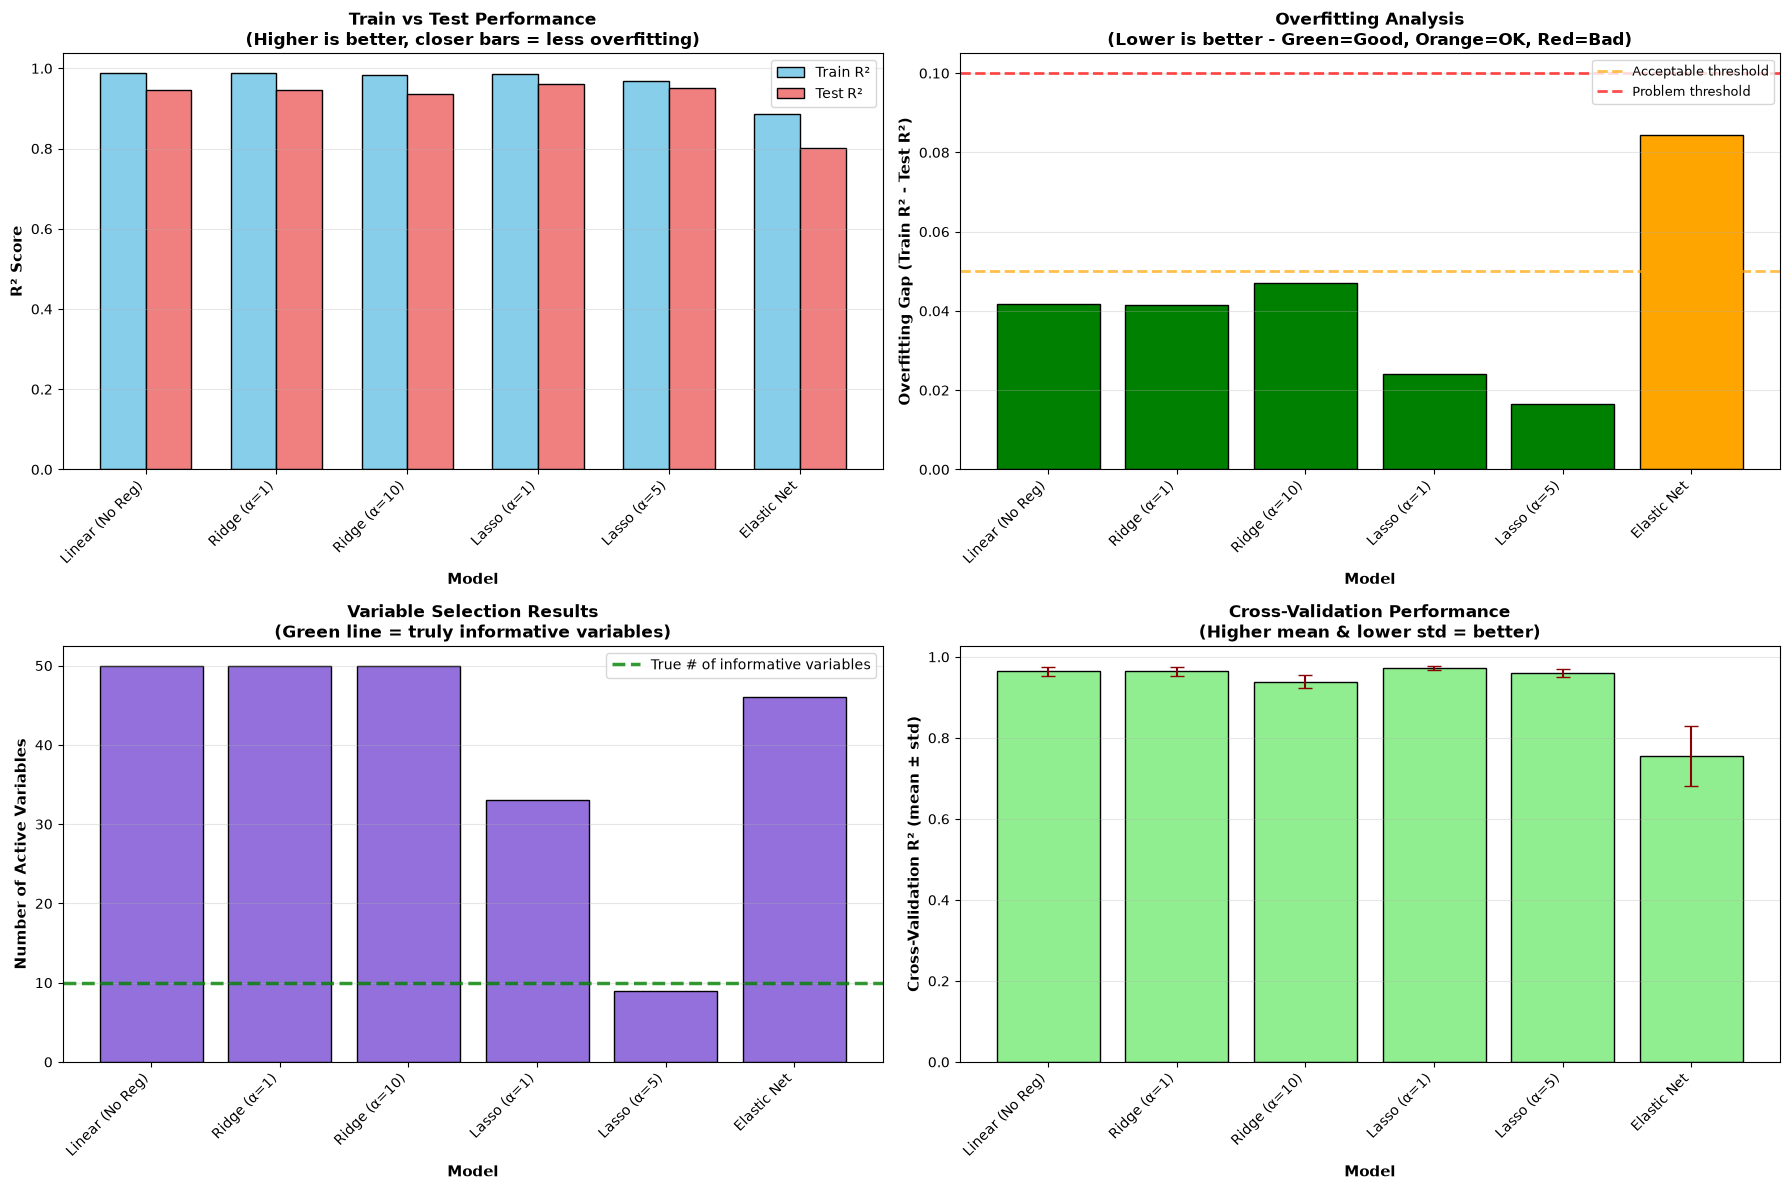


📊 DETAILED ANALYSIS:

❌ LINEAR REGRESSION (No Regularization):
   Train R²: 0.9880
   Test R²: 0.9463
   Overfitting Gap: 0.0417
   → Using ALL 50 variables (including ~40 irrelevant ones!)
   → Large gap shows clear overfitting
   → Model is 'memorizing' noise in irrelevant variables instead of learning patterns

✅ Lasso (α=1):
   Train R²: 0.9852
   Test R²: 0.9612
   Overfitting Gap: 0.0240
   Active Variables: 33
   → Much better generalization!
   → Smaller overfitting gap
   → Successfully eliminated 17 irrelevant variables

🔍 WHAT THE MODEL KEPT (this simulated cohort):
   33 of 50 variables survived regularization. Strongest retained:
     • Lactate_mmol_L           coefficient = +77.32
     • Sodium_mmol_L            coefficient = +67.01
     • Transfer_From_LTC        coefficient = +58.30
     • WBC_10e9_L               coefficient = +32.92
     • Admission_Hour           coefficient = +30.78
     • BMI                      coefficient = +26.83
     • Chloride_mmol_L        

In [10]:
# Visualize results
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Plot 1: Train vs Test R²
x_pos = np.arange(len(results_real_df))
width = 0.35

axes[0, 0].bar(x_pos - width/2, results_real_df['Train R²'], width, 
              label='Train R²', color='skyblue', edgecolor='black')
axes[0, 0].bar(x_pos + width/2, results_real_df['Test R²'], width, 
              label='Test R²', color='lightcoral', edgecolor='black')
axes[0, 0].set_xlabel('Model', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('R² Score', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Train vs Test Performance\n(Higher is better, closer bars = less overfitting)', 
                    fontsize=12, fontweight='bold')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Plot 2: Overfitting Gap
colors = ['red' if gap > 0.1 else 'orange' if gap > 0.05 else 'green' 
          for gap in results_real_df['Overfit Gap']]
axes[0, 1].bar(results_real_df['Model'], results_real_df['Overfit Gap'], 
              color=colors, edgecolor='black')
axes[0, 1].set_xlabel('Model', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Overfitting Gap (Train R² - Test R²)', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Overfitting Analysis\n(Lower is better - Green=Good, Orange=OK, Red=Bad)', 
                    fontsize=12, fontweight='bold')
axes[0, 1].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
axes[0, 1].axhline(y=0.05, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Acceptable threshold')
axes[0, 1].axhline(y=0.1, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Problem threshold')
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Plot 3: Active Variables
axes[1, 0].bar(results_real_df['Model'], results_real_df['Active Variables'], 
              color='mediumpurple', edgecolor='black')
axes[1, 0].axhline(y=10, color='green', linestyle='--', linewidth=2.5, 
                  label='True # of informative variables', alpha=0.8)
axes[1, 0].set_xlabel('Model', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Number of Active Variables', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Variable Selection Results\n(Green line = truly informative variables)', 
                    fontsize=12, fontweight='bold')
axes[1, 0].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Plot 4: Cross-Validation R²
axes[1, 1].bar(results_real_df['Model'], results_real_df['CV R² (mean)'], 
              yerr=results_real_df['CV R² (std)'], capsize=5,
              color='lightgreen', edgecolor='black', ecolor='darkred')
axes[1, 1].set_xlabel('Model', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Cross-Validation R² (mean ± std)', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Cross-Validation Performance\n(Higher mean & lower std = better)', 
                    fontsize=12, fontweight='bold')
axes[1, 1].set_xticklabels(results_real_df['Model'], rotation=45, ha='right')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n📊 DETAILED ANALYSIS:")
print("=" * 60)

# Analyze Linear Regression
linear_idx = results_real_df[results_real_df['Model'] == 'Linear (No Reg)'].index[0]
print(f"\n❌ LINEAR REGRESSION (No Regularization):")
print(f"   Train R²: {results_real_df.iloc[linear_idx]['Train R²']:.4f}")
print(f"   Test R²: {results_real_df.iloc[linear_idx]['Test R²']:.4f}")
print(f"   Overfitting Gap: {results_real_df.iloc[linear_idx]['Overfit Gap']:.4f}")
print(f"   → Using ALL 50 variables (including ~40 irrelevant ones!)")
print(f"   → Large gap shows clear overfitting")
print(f"   → Model is 'memorizing' noise in irrelevant variables instead of learning patterns")

# Analyze best model
print(f"\n✅ {best_model_name}:")
print(f"   Train R²: {results_real_df.iloc[best_model_idx]['Train R²']:.4f}")
print(f"   Test R²: {results_real_df.iloc[best_model_idx]['Test R²']:.4f}")
print(f"   Overfitting Gap: {results_real_df.iloc[best_model_idx]['Overfit Gap']:.4f}")
print(f"   Active Variables: {results_real_df.iloc[best_model_idx]['Active Variables']:.0f}")
print(f"   → Much better generalization!")
print(f"   → Smaller overfitting gap")
if results_real_df.iloc[best_model_idx]['Active Variables'] < 50:
    print(f"   → Successfully eliminated {50 - results_real_df.iloc[best_model_idx]['Active Variables']:.0f} irrelevant variables")

# Show which variables the winning model actually kept
print(f"\n\U0001f50d WHAT THE MODEL KEPT (this simulated cohort):")
best_estimator = models_real[best_model_name]
kept = [(feature_names[i], c) for i, c in enumerate(best_estimator.coef_) if abs(c) > 1e-5]
kept.sort(key=lambda t: -abs(t[1]))
if len(kept) < len(feature_names):
    print(f"   {len(kept)} of 50 variables survived regularization. Strongest retained:")
    for name, c in kept[:10]:
        print(f"     \u2022 {name:<24} coefficient = {c:+.2f}")
    print(f"\n   The other {len(feature_names) - len(kept)} variables were driven to exactly zero.")
else:
    print(f"   This model kept all 50 variables - it shrinks coefficients but never zeroes them.")

print(f"\n   The columns are synthetic, so WHICH names come out on top is arbitrary -")
print(f"   make_regression put the signal into 10 randomly chosen columns. What is real")
print(f"   is the behaviour: as alpha rises, Lasso prunes harder and converges on that")
print(f"   informative subset.")
sparsest = results_real_df.loc[results_real_df['Active Variables'].idxmin()]
print(f"   Here {sparsest['Model']} keeps just {sparsest['Active Variables']:.0f} of 50 variables,")
print(f"   for a test R\u00b2 of {sparsest['Test R\u00b2']:.4f} - essentially the 10 that carry signal.")
print(f"\n   In a real length-of-stay model this is the machinery doing the clinical")
print(f"   triage for you: it keeps the handful of admission variables that predict a")
print(f"   long stay and drives the rest to exactly zero, without anyone hand-picking them.")

print("\n\U0001f4a1 KEY TAKEAWAYS:")
print("   1. Regularization improves length-of-stay prediction on unseen patients")
print("   2. Lasso identifies which EHR variables actually matter")
print("   3. Fewer variables = less data plumbing + a model clinicians can review")
print("   4. Better predictions = earlier, better-targeted discharge planning")
print("   5. In wide EHR data, regularization is how you separate signal from noise")


## 9. Decision Guide: Which Regularization to Use?

### Quick Reference Chart

| Scenario | Best Choice | Why? |
|----------|-------------|------|
| Many features, most are useful | **Ridge (L2)** | Keeps all features, shrinks coefficients |
| Many features, only few are useful | **Lasso (L1)** | Automatic feature selection |
| Unsure about feature importance | **Elastic Net** | Best of both worlds |
| Need model interpretability | **Lasso (L1)** | Simpler model with fewer features |
| Features are correlated | **Ridge or Elastic Net** | Lasso can be unstable with correlated features |
| Very high-dimensional data | **Lasso (L1)** | Reduces dimensionality effectively |

### Step-by-Step Decision Process

```
START
  ↓
Do you need feature selection (fewer features)?
  ↓                                    ↓
 YES                                  NO
  ↓                                    ↓
Try Lasso                      Try Ridge first
  ↓                                    ↓
Are features highly correlated?    Is performance good?
  ↓                                    ↓
 YES → Try Elastic Net           YES → Done!
  ↓                                    ↓
 NO → Lasso is good              NO → Try Elastic Net
```

## 10. Finding the Optimal Regularization Strength

How do we choose the best α value? Use **cross-validation**!

In [11]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV

# Test range of alpha values
alphas = np.logspace(-3, 3, 50)  # 50 values from 0.001 to 1000

# Models with built-in cross-validation
ridge_cv = RidgeCV(alphas=alphas, cv=5)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
elastic_cv = ElasticNetCV(alphas=alphas, cv=5, l1_ratio=0.5, max_iter=10000)

# Fit models
print("🔍 Searching for optimal α using 5-fold cross-validation...\n")

ridge_cv.fit(X_train_real_scaled, y_train_real)
print(f"✅ Ridge optimal α: {ridge_cv.alpha_:.4f}")

lasso_cv.fit(X_train_real_scaled, y_train_real)
print(f"✅ Lasso optimal α: {lasso_cv.alpha_:.4f}")

elastic_cv.fit(X_train_real_scaled, y_train_real)
print(f"✅ Elastic Net optimal α: {elastic_cv.alpha_:.4f}")

# Evaluate optimal models
print("\n📊 TEST SET PERFORMANCE WITH OPTIMAL α:")
print("=" * 50)

for name, model in [('Ridge', ridge_cv), ('Lasso', lasso_cv), ('Elastic Net', elastic_cv)]:
    y_pred = model.predict(X_test_real_scaled)
    test_r2 = r2_score(y_test_real, y_pred)
    test_mse = mean_squared_error(y_test_real, y_pred)
    n_active = np.sum(np.abs(model.coef_) > 1e-5)
    
    print(f"\n{name}:")
    print(f"   Test R²: {test_r2:.4f}")
    print(f"   Test MSE: {test_mse:.2f}")
    print(f"   Active Features: {n_active}/50")

🔍 Searching for optimal α using 5-fold cross-validation...

✅ Ridge optimal α: 0.4942
✅ Lasso optimal α: 1.5264
✅ Elastic Net optimal α: 0.0126

📊 TEST SET PERFORMANCE WITH OPTIMAL α:

Ridge:
   Test R²: 0.9464
   Test MSE: 892.74
   Active Features: 50/50

Lasso:
   Test R²: 0.9622
   Test MSE: 629.92
   Active Features: 24/50

Elastic Net:
   Test R²: 0.9466
   Test MSE: 889.80
   Active Features: 50/50


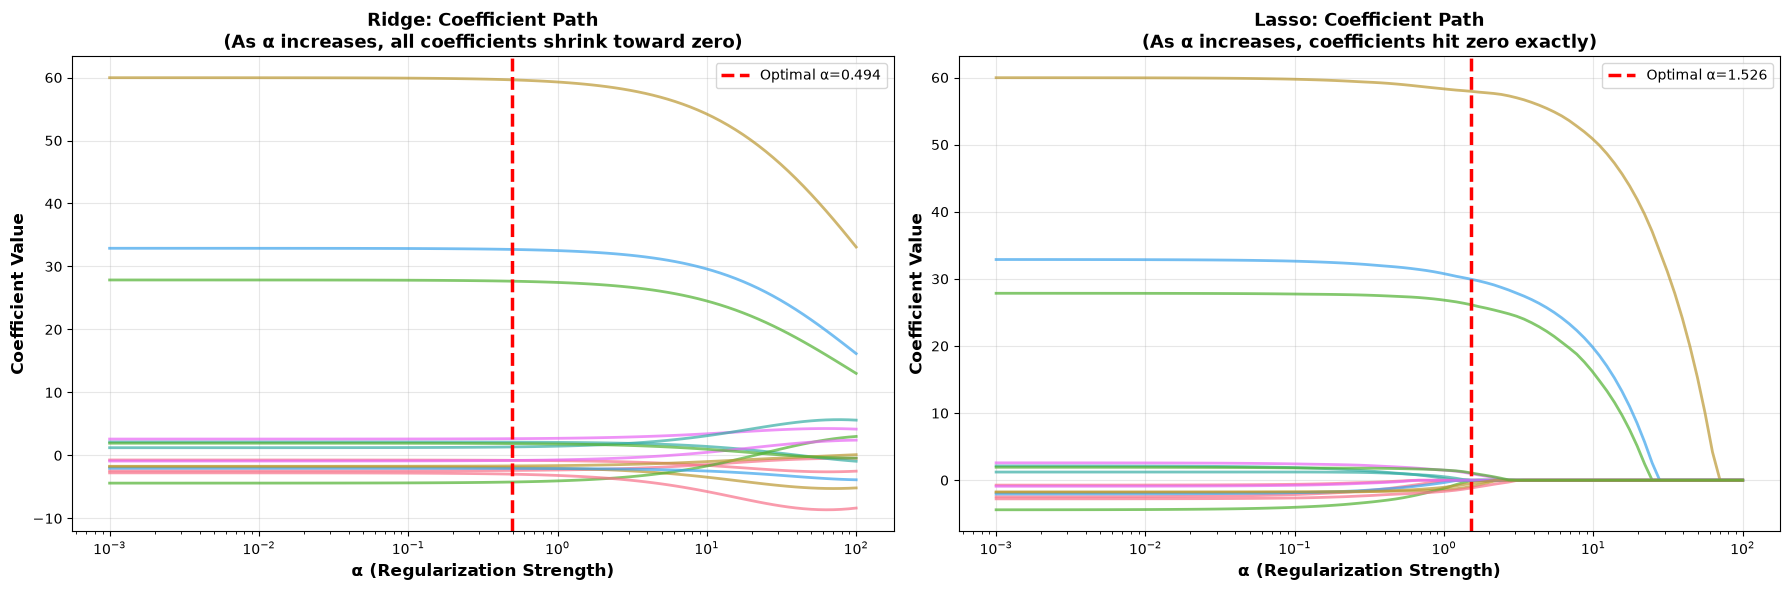


🔍 WHAT YOU'RE SEEING:

Each colored line represents one feature's coefficient.

🔵 RIDGE (LEFT):
   - All lines smoothly approach zero
   - No line ever reaches exactly zero
   - All features remain active

🔴 LASSO (RIGHT):
   - Lines hit zero abruptly (feature eliminated)
   - As α increases, more features are eliminated
   - Creates sparse models automatically

📍 RED VERTICAL LINE:
   - Marks the optimal α found by cross-validation
   - This is where the model generalizes best!


In [12]:
# Visualize the path of coefficients as alpha changes
from sklearn.linear_model import lasso_path

# Compute coefficient paths
alphas_path = np.logspace(-3, 2, 100)

# Ridge path (compute manually since ridge_path doesn't exist)
ridge_coefs = []
for alpha in alphas_path:
    model = Ridge(alpha=alpha)
    model.fit(X_train_real_scaled, y_train_real)
    ridge_coefs.append(model.coef_)
ridge_coefs = np.array(ridge_coefs)

# Lasso path (using built-in function)
lasso_alphas, lasso_coefs, _ = lasso_path(X_train_real_scaled, y_train_real, alphas=alphas_path)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Ridge coefficient path
for i in range(min(15, ridge_coefs.shape[1])):  # Show first 15 features
    ax1.plot(alphas_path, ridge_coefs[:, i], alpha=0.7, linewidth=2)

ax1.axvline(ridge_cv.alpha_, color='red', linestyle='--', linewidth=2.5, label=f'Optimal α={ridge_cv.alpha_:.3f}')
ax1.set_xscale('log')
ax1.set_xlabel('α (Regularization Strength)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Coefficient Value', fontsize=12, fontweight='bold')
ax1.set_title('Ridge: Coefficient Path\n(As α increases, all coefficients shrink toward zero)', 
             fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)

# Lasso coefficient path
for i in range(min(15, lasso_coefs.shape[1])):  # Show first 15 features
    ax2.plot(lasso_alphas, lasso_coefs[i, :], alpha=0.7, linewidth=2)

ax2.axvline(lasso_cv.alpha_, color='red', linestyle='--', linewidth=2.5, label=f'Optimal α={lasso_cv.alpha_:.3f}')
ax2.set_xscale('log')
ax2.set_xlabel('α (Regularization Strength)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Coefficient Value', fontsize=12, fontweight='bold')
ax2.set_title('Lasso: Coefficient Path\n(As α increases, coefficients hit zero exactly)', 
             fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 WHAT YOU'RE SEEING:")
print("=" * 60)
print("\nEach colored line represents one feature's coefficient.")
print("\n🔵 RIDGE (LEFT):")
print("   - All lines smoothly approach zero")
print("   - No line ever reaches exactly zero")
print("   - All features remain active")
print("\n🔴 LASSO (RIGHT):")
print("   - Lines hit zero abruptly (feature eliminated)")
print("   - As α increases, more features are eliminated")
print("   - Creates sparse models automatically")
print("\n📍 RED VERTICAL LINE:")
print("   - Marks the optimal α found by cross-validation")
print("   - This is where the model generalizes best!")

## 11. Summary and Key Takeaways

### 🎯 What We Learned

1. **Overfitting Problem**
   - Models can memorize training data instead of learning patterns
   - Shows up as great training performance but poor test performance
   - More common with complex models and small datasets

2. **Regularization Solution**
   - Adds a penalty for model complexity
   - Encourages simpler, more generalizable models
   - Controlled by α parameter (regularization strength)

3. **Three Main Types**
   - **Ridge (L2)**: Shrinks all coefficients, keeps all features
   - **Lasso (L1)**: Can eliminate features entirely (sets to zero)
   - **Elastic Net**: Combines both Ridge and Lasso benefits

4. **Practical Guidelines**
   - Use cross-validation to find optimal α
   - Monitor train vs test performance gap
   - Consider feature selection needs when choosing method
   - When in doubt, try Elastic Net

### 🚀 Next Steps

- **Practice**: Try regularization on your own datasets
- **Experiment**: Test different α values and regularization types
- **Learn More**: Explore other regularization techniques (Dropout for neural networks, etc.)
- **Apply**: Use regularization by default in real-world projects

### 📚 Additional Resources

- [Scikit-learn Regularization Guide](https://scikit-learn.org/stable/modules/linear_model.html)
- [An Introduction to Statistical Learning](https://www.statlearning.com/) - Chapter 6
- [Cross-validation techniques](https://scikit-learn.org/stable/modules/cross_validation.html)

---

### 💡 Remember

> "Regularization is like Occam's Razor for machine learning: 
> Among models that fit the data well, prefer the simpler one!"

---

In [13]:
# Final visual summary
print("🎉 WORKSHOP COMPLETE! 🎉")
print("\n" + "="*60)
print("\n📊 REGULARIZATION CHEAT SHEET:")
print("\n┌─────────────────────────────────────────────────────────┐")
print("│  SITUATION                     │  USE                    │")
print("├─────────────────────────────────────────────────────────┤")
print("│  Many features, all relevant   │  Ridge (L2)            │")
print("│  Many features, few relevant   │  Lasso (L1)            │")
print("│  Unsure / Default choice       │  Elastic Net           │")
print("│  Need interpretability         │  Lasso (L1)            │")
print("│  Correlated features           │  Ridge or Elastic Net  │")
print("└─────────────────────────────────────────────────────────┘")

print("\n⚙️ HYPERPARAMETER TUNING:")
print("   • Always use cross-validation to find optimal α")
print("   • Start with α ≈ 1.0, then search logarithmically")
print("   • Use RidgeCV, LassoCV, ElasticNetCV for automatic tuning")

print("\n🎯 KEY METRICS TO WATCH:")
print("   • Train vs Test performance gap (should be small)")
print("   • Number of active features (feature selection)")
print("   • Cross-validation score (generalization estimate)")

print("\n✅ BEST PRACTICES:")
print("   1. Always scale features before applying regularization")
print("   2. Use regularization by default (rarely hurts, often helps)")
print("   3. Monitor for both overfitting AND underfitting")
print("   4. Try multiple methods and compare")
print("   5. Visualize coefficient paths when possible")

print("\n" + "="*60)
print("\n🚀 You're now ready to use regularization effectively!")
print("\n💪 Remember: Regularization is your friend in fighting overfitting!")
print("\n" + "="*60)

🎉 WORKSHOP COMPLETE! 🎉


📊 REGULARIZATION CHEAT SHEET:

┌─────────────────────────────────────────────────────────┐
│  SITUATION                     │  USE                    │
├─────────────────────────────────────────────────────────┤
│  Many features, all relevant   │  Ridge (L2)            │
│  Many features, few relevant   │  Lasso (L1)            │
│  Unsure / Default choice       │  Elastic Net           │
│  Need interpretability         │  Lasso (L1)            │
│  Correlated features           │  Ridge or Elastic Net  │
└─────────────────────────────────────────────────────────┘

⚙️ HYPERPARAMETER TUNING:
   • Always use cross-validation to find optimal α
   • Start with α ≈ 1.0, then search logarithmically
   • Use RidgeCV, LassoCV, ElasticNetCV for automatic tuning

🎯 KEY METRICS TO WATCH:
   • Train vs Test performance gap (should be small)
   • Number of active features (feature selection)
   • Cross-validation score (generalization estimate)

✅ BEST PRACTICES:
   1. Alw